In [2]:
import numpy as np
import scqubits as scq
import qutip as qt
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

In [3]:
transmon = scq.Transmon(EJ=16.0, EC=0.18127, ng=0.0, ncut=30)
evals = transmon.eigenvals(evals_count=3)

#anharmonicity (rad/ns)
alpha = 2 * np.pi * (evals[2] - 2*evals[1] + evals[0])

print(f"Anharmonicity: {alpha/(2*np.pi)*1000:.1f} MHz")

Anharmonicity: -200.0 MHz


In [4]:
#parameters:

dim = 3
T_pulse = 16.0  #ns
T_sim = 20.0  #ns
n_steps = 500 #resolution
detuning = 0.001 * 2 * np.pi # 1 MHz
phi = np.pi / 2 #Y rotation

#operators
a = qt.destroy(dim)
adag = a.dag()

#hamiltonian (rotating frame)
H_drift = (alpha / 2.0) * adag * adag * a * a

In [5]:
#Pulse shapes:

def hann_shape(t, T):
    """
    Using a Hann (cosine) envelope instead of a truncated Gaussian.
    This guarantees that both the amplitude AND the slope are exactly 0 at t=0 and t=T,
    eliminating abrupt high-frequency splatter.
    """
    if t < 0 or t > T: return 0.0
    return 0.5 * (1.0 - np.cos(2 * np.pi * t / T))

def deriv_hann(t, T):
    """
    The exact analytical derivative of the Hann envelope.
    Notice that sin(0) = 0 and sin(2*pi) = 0, so the DRAG component also starts and ends at 0.
    """
    if t < 0 or t > T: return 0.0
    return 0.5 * (2 * np.pi / T) * np.sin(2 * np.pi * t / T)


def make_coeffs(amp, lambda_val):
    """
    control coeffs
    lambda is tunable drag parameter
    eq 101 in Krantz:
    Ox = amp * s(t) (rotation around x, I component)
    Oy = amp * lambda/alpha * ds/dt (rot around y, Q comp)
    """
    def coeff(t, args):
        if t > T_pulse: return 0.0

        #main drive
        Ox = amp * hann_shape(t, T_pulse)

        #drag correction
        ds_dt = deriv_hann(t, T_pulse)
        Oy = amp * lambda_val * ds_dt / alpha

        #complete formula
        envelope = -0.5 * (Ox - 1j * Oy)
        phase = np.exp(1j * (detuning * t + phi))

        return envelope * phase

    def coeff_conj(t, args):
        return np.conj(coeff(t, args))

    return coeff, coeff_conj

In [6]:
#calibration functions:

def get_fidelity(amp, lambda_val):
    '''
    we start at psi0 (ground state, before applying pulse)
    then we apply drive
    then we compare our final state with the first excited state
    which is qt.basis(dim,1), and this gives fidelity
    we use loose tolerance (10^-5) for speed
    smaller tolerance means more accuracy but slower
    '''
    cp, cm = make_coeffs(amp, lambda_val)
    H = [H_drift, [adag, cp], [a, cm]] #hamiltonian
    psi0 = qt.basis(dim, 0)
    tlist = np.linspace(0, T_pulse, n_steps)

    res = qt.sesolve(H, psi0, tlist, args={}, options={'rtol':1e-5})
    return np.abs(res.states[-1].overlap(qt.basis(dim, 1)))**2


def optimize_amp(lambda_val):
    '''
    Rough guess for amplitude
    The integral of a Hann pulse over time T is (0.5 * T)
    Area = pi for a pi pulse
    -> amp = pi / (0.5 * T_pulse * n01)
    '''
    n01 = np.abs(transmon.matrixelement_table("n_operator")[0, 1])

    # updated guess for the Hann pulse area
    guess = np.pi / (0.5 * T_pulse * n01)

    res = minimize_scalar(
        lambda x: 1.0 - get_fidelity(x, lambda_val),
        bounds=(guess*0.7, guess*1.3),
        method='bounded'
    )
    return res.x, 1.0 - res.fun

In [7]:
#calibration sweep:

print("\n Sweeping Lambda:")
#we sweep a wide range because we don't know where the optimal will land
lambdas = np.linspace(-1.0, 2.0, 51)
fids = []
amps = []

for l in lambdas:
    a_opt, f_opt = optimize_amp(l)
    amps.append(a_opt)
    fids.append(f_opt)

#find the best values
best_idx = np.argmax(fids)
best_lambda = lambdas[best_idx]
best_fid = fids[best_idx]
best_amp = amps[best_idx]

#find for the standard (lambda=0)
std_idx = np.argmin(np.abs(lambdas - 0.0))
std_fid = fids[std_idx]
std_amp = amps[std_idx]

print(f"Standard (Lambda=0): Fid = {std_fid:.5f}")
print(f"With DRAG  (Lambda={best_lambda:.2f}): Fid = {best_fid:.5f}")



 Sweeping Lambda:


 /usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py: 199

Standard (Lambda=0): Fid = 0.97766
With DRAG  (Lambda=0.56): Fid = 0.99995


In [8]:
#for plots:

def run_full_sim(amp, lambda_val):
    cp, cm = make_coeffs(amp, lambda_val)
    H = [H_drift, [adag, cp], [a, cm]]
    psi0 = qt.basis(dim, 0)
    dt = T_pulse / n_steps
    tlist = np.linspace(0, T_sim, int(T_sim/dt))
    return qt.sesolve(H, psi0, tlist, args={}), tlist

res_s, t_s = run_full_sim(std_amp, 0.0) #standard
res_d, t_d = run_full_sim(best_amp, best_lambda) #drag

p0_s = [np.abs(st.overlap(qt.basis(dim, 0)))**2 for st in res_s.states]
p1_s = [np.abs(st.overlap(qt.basis(dim, 1)))**2 for st in res_s.states]
p2_s = [np.abs(st.overlap(qt.basis(dim, 2)))**2 for st in res_s.states]

p0_d = [np.abs(st.overlap(qt.basis(dim, 0)))**2 for st in res_d.states]
p1_d = [np.abs(st.overlap(qt.basis(dim, 1)))**2 for st in res_d.states]
p2_d = [np.abs(st.overlap(qt.basis(dim, 2)))**2 for st in res_d.states]

 <>: 23SyntaxWarning: invalid escape sequence '\p'
 <>: 23SyntaxWarning: invalid escape sequence '\p'
 /tmp/ipykernel_599/3676875232.py: 23

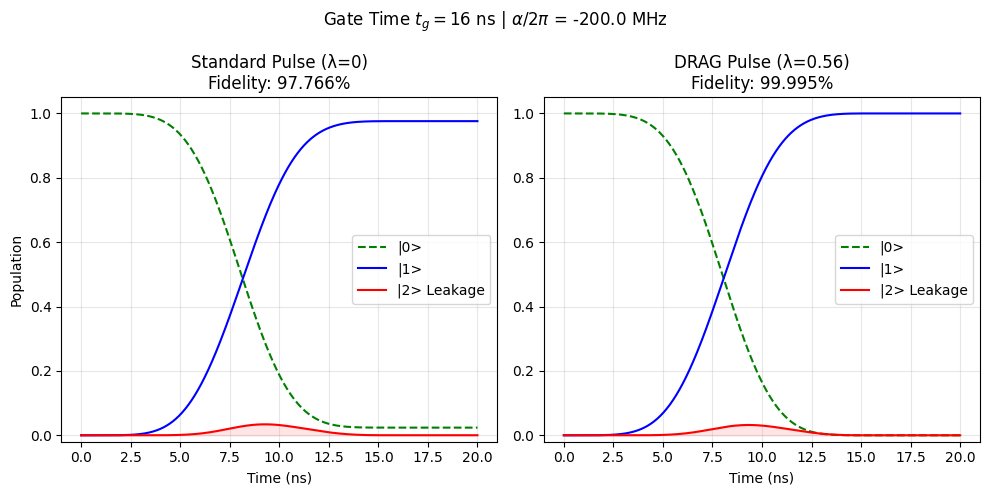

In [9]:
#figure 1: populations
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

#standard pulse
ax1.plot(t_s, p0_s, 'g--', label='|0>')
ax1.plot(t_s, p1_s, 'b', label='|1>')
ax1.plot(t_s, p2_s, 'r', label='|2> Leakage')
ax1.fill_between(t_s, p2_s, color='red', alpha=0.1)
ax1.set_title(f"Standard Pulse (λ=0)\nFidelity: {std_fid*100:.3f}%")
ax1.set_xlabel("Time (ns)")
ax1.set_ylabel("Population")
ax1.set_ylim(-0.02, 1.05); ax1.legend(); ax1.grid(True, alpha=0.3)

#DRAG pulse
ax2.plot(t_d, p0_d, 'g--', label='|0>')
ax2.plot(t_d, p1_d, 'b', label='|1>')
ax2.plot(t_d, p2_d, 'r', label='|2> Leakage')
ax2.fill_between(t_d, p2_d, color='red', alpha=0.1)
ax2.set_title(f"DRAG Pulse (λ={best_lambda:.2f})\nFidelity: {best_fid*100:.3f}%")
ax2.set_xlabel("Time (ns)")
ax2.set_ylim(-0.02, 1.05); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle(f"Gate Time $t_g = 16$ ns | $\\alpha/2\pi$ = {alpha/(2*np.pi)*1000:.1f} MHz")
plt.tight_layout()
plt.show()

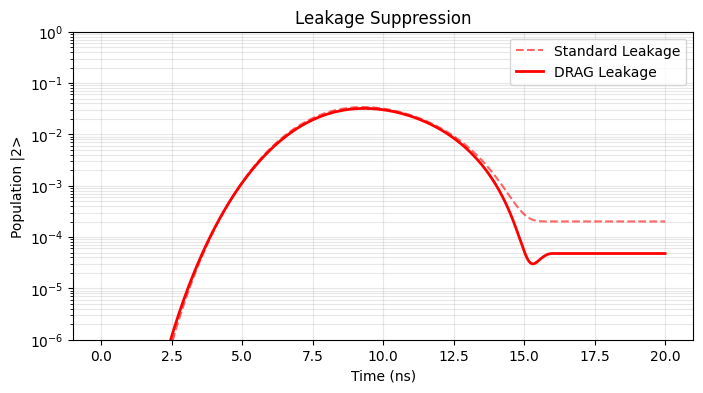

In [10]:
#fig 2 log scale leakage
plt.figure(figsize=(8, 4))
plt.semilogy(t_s, p2_s, 'r--', label='Standard Leakage', alpha=0.6)
plt.semilogy(t_d, p2_d, 'r', label='DRAG Leakage', linewidth=2)
plt.title("Leakage Suppression")
plt.xlabel("Time (ns)")
plt.ylabel("Population |2>")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.ylim(1e-6, 1.0)
plt.show()

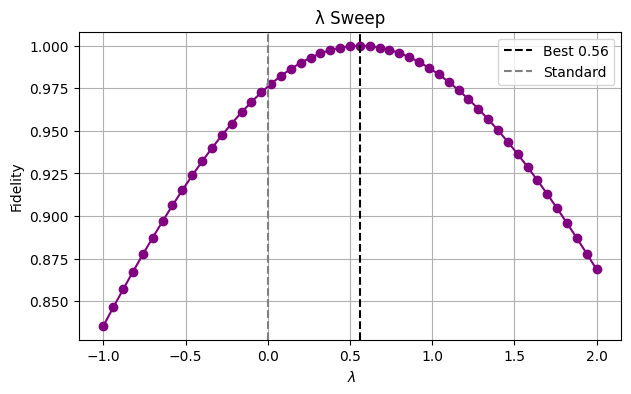

In [11]:
#figure 3 lambda
plt.figure(figsize=(7, 4))
plt.plot(lambdas, fids, 'o-', color='purple')
plt.axvline(best_lambda, color='k', linestyle='--', label=f'Best {best_lambda:.2f}')
plt.axvline(0.0, color='gray', linestyle='--', label='Standard')
plt.xlabel(r" $\lambda$")
plt.ylabel("Fidelity")
plt.title("λ Sweep")
plt.legend()
plt.grid(True)
plt.show()


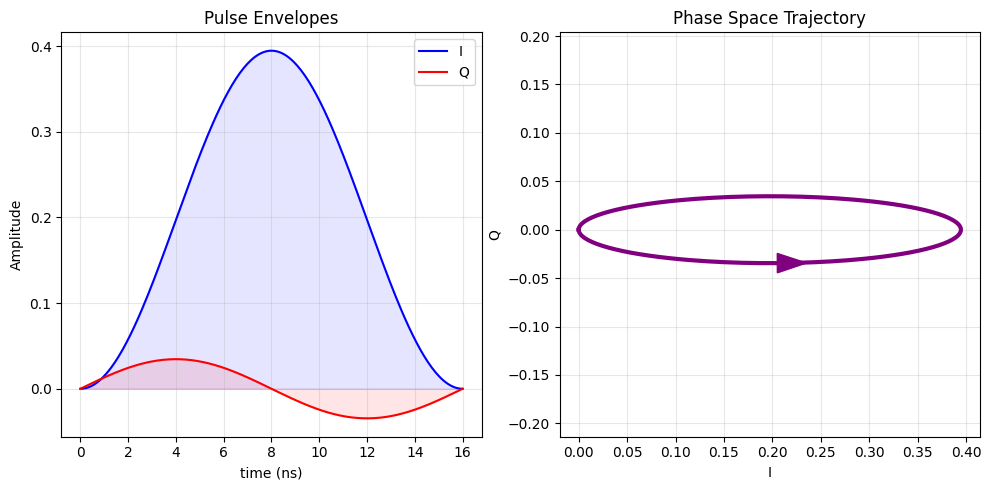

In [12]:
#fig 4 pulse trajectories

t_p = np.linspace(0, T_pulse, 200)
I_vals = best_amp * np.array([hann_shape(t, T_pulse) for t in t_p])
ds_vals = np.array([deriv_hann(t, T_pulse) for t in t_p])

#pure lambda scaling
Q_vals = best_amp * best_lambda * ds_vals / alpha

fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(10, 5))
ax3a.plot(t_p, I_vals, 'b', label='I')
ax3a.plot(t_p, -Q_vals, 'r', label='Q')
ax3a.fill_between(t_p, I_vals, alpha=0.1, color='b')
ax3a.fill_between(t_p, -Q_vals, alpha=0.1, color='r')
ax3a.set_xlabel("time (ns)"); ax3a.set_ylabel("Amplitude")
ax3a.set_title("Pulse Envelopes")
ax3a.grid(True, alpha=0.3); ax3a.legend()

ax3b.plot(I_vals, Q_vals, 'purple', linewidth=3)
idx_qtr = len(I_vals) // 4
ax3b.arrow(I_vals[idx_qtr], Q_vals[idx_qtr],
           I_vals[idx_qtr+1]-I_vals[idx_qtr], Q_vals[idx_qtr+1]-Q_vals[idx_qtr],
           head_width=0.02, color='purple')
ax3b.set_title("Phase Space Trajectory")
ax3b.set_xlabel("I"); ax3b.set_ylabel("Q")
ax3b.axis('equal'); ax3b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

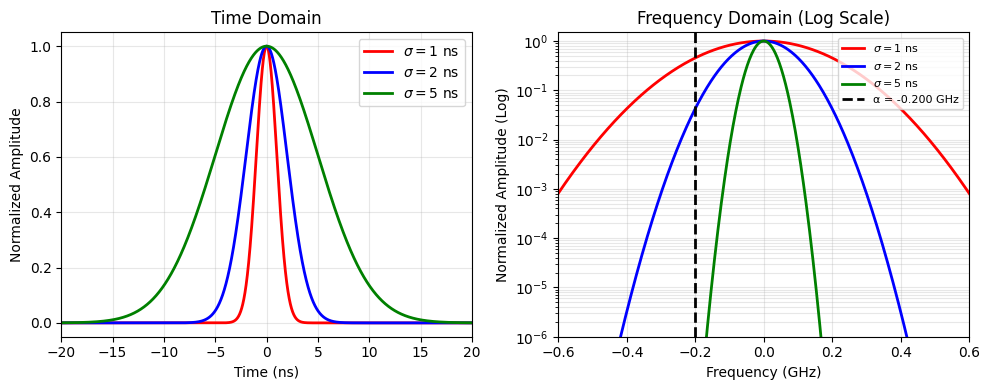

In [13]:
#fig 5 spectral analysis
'''
if we have higher anharmonicity (more negative)
we would have less leak for smaller sigma values as well
'''
import numpy.fft as fft

T_fft = 500.0 # ns
dt_fft = 0.01 #ns
t_fft = np.linspace(-T_fft/2, T_fft/2, int(T_fft/dt_fft))

#converting alpha (rad/ns) to (linear) frequency GHz for fft
leak_freq = alpha / (2 * np.pi)

#compare widths
sigmas = [1.0, 2.0, 5.0]
labels = [r'$\sigma=1$ ns', r'$\sigma=2$ ns', r'$\sigma=5$ ns']
colors = ['red', 'blue', 'green']


#plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

for sig, col, lab in zip(sigmas, colors, labels):
    #time domain
    #gaussian centered at 0
    envelope = np.exp(-t_fft**2 / (2 * sig**2))
    #normalize height for comparison
    envelope_norm = envelope / np.max(envelope)

    ax1.plot(t_fft, envelope_norm, color=col, linewidth=2, label=lab)

    #freq domain (fft)
    #compute fft
    spectrum = np.abs(fft.fftshift(fft.fft(envelope)))
    #freq axis
    freqs = fft.fftshift(fft.fftfreq(len(t_fft), d=dt_fft))

    #normalize spectrum
    spectrum_norm = spectrum / np.max(spectrum)

    ax2.plot(freqs, spectrum_norm, color=col, linewidth=2, label=lab)


#time plot
ax1.set_title("Time Domain")
ax1.set_xlabel("Time (ns)")
ax1.set_ylabel("Normalized Amplitude")
ax1.set_xlim(-20, 20)
ax1.grid(True, alpha=0.3)
ax1.legend()

#freq plot
#anharmonicity line
ax2.axvline(x=leak_freq, color='k', linestyle='--', linewidth=2, label=f'α = {leak_freq:.3f} GHz')

ax2.set_title("Frequency Domain (Log Scale)")
ax2.set_xlabel("Frequency (GHz)")
ax2.set_ylabel("Normalized Amplitude (Log)")
ax2.set_xlim(-0.6, 0.6)

#logarithmic y-axis
ax2.set_yscale('log')
ax2.set_ylim(1e-6, 1.5) #sets the bottom floor so it doesn't drop to negative infinity

ax2.grid(True, which="both", alpha=0.3) # "both" turns on grids for the log sub-ticks
ax2.legend(loc='upper right', prop={'size': 8})

plt.tight_layout()
plt.show()